# K-Means Clustering — Spotify Song Characteristics

**University coursework | Artificial Intelligence — Faculty of Organizational Sciences, University of Belgrade**

This notebook explores clustering of songs using selected numeric Spotify-related attributes.

K-means is an **unsupervised** algorithm: there is no target value or prediction accuracy here. The purpose is to see which songs have similar feature patterns.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
import sklearn.cluster as cluster
from scipy.stats.mstats import winsorize
from sklearn.preprocessing import MinMaxScaler


## 1. Load and inspect the data

Read the supplied `spotify.csv` file and examine its columns.

In [2]:
df = pd.read_csv('spotify.csv', na_values=['-',' ', ''])
print(df.info())
display(df.head())


<class 'pandas.DataFrame'>
RangeIndex: 953 entries, 0 to 952
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   track_name            953 non-null    str    
 1   released_year         953 non-null    int64  
 2   in_spotify_playlists  953 non-null    int64  
 3   in_spotify_charts     951 non-null    float64
 4   streams               953 non-null    int64  
 5   in_apple_playlists    953 non-null    int64  
 6   in_apple_charts       951 non-null    float64
 7   bpm                   953 non-null    int64  
 8   mode                  953 non-null    str    
 9   energy                953 non-null    int64  
 10  instrumentalness      953 non-null    int64  
 11  liveness              953 non-null    int64  
 12  speechiness           953 non-null    int64  
dtypes: float64(2), int64(9), str(2)
memory usage: 96.9 KB
None


,track_name,released_year,in_spotify_playlists,in_spotify_charts,streams,in_apple_playlists,in_apple_charts,bpm,mode,energy,instrumentalness,liveness,speechiness
0,Seven (feat. Latto) (Explicit Ver.),2023,553,147.0,141381703,43,263.0,125,Major,83,0,8,4
1,LALA,2023,1474,48.0,133716286,48,126.0,92,Major,74,0,10,4
2,vampire,2023,1397,113.0,140003974,94,207.0,138,Major,53,0,31,6
3,Cruel Summer,2019,7858,NaN,800840817,116,207.0,170,Major,72,0,11,15
4,WHERE SHE GOES,2023,3133,50.0,303236322,84,133.0,144,Minor,80,63,11,6


## 2. Prepare the dataset

The exercise retains songs with `speechiness` up to 60, removes non-numeric `track_name` and near-constant `instrumentalness`, encodes `mode` as 0 or 1, and converts the charts column to a numeric type.

In [3]:
df_subset = df[df['speechiness']<=60].copy()

print(df_subset.isna().sum())

df_subset = df_subset.drop(columns='track_name')

df_subset['mode'] = df_subset['mode'].map({'Major':0, 'Minor':1})

print(df_subset.describe())

df_subset = df_subset.drop(columns='instrumentalness')

df_subset['in_spotify_charts'] = pd.to_numeric(df_subset['in_spotify_charts'],errors='coerce')


track_name              0
released_year           0
in_spotify_playlists    0
in_spotify_charts       2
streams                 0
in_apple_playlists      0
in_apple_charts         2
bpm                     0
mode                    0
energy                  0
instrumentalness        0
liveness                0
speechiness             0
dtype: int64
       released_year  in_spotify_playlists  in_spotify_charts       streams  \
count     952.000000            952.000000         950.000000  9.520000e+02   
mean     2018.233193           5205.304622          11.880000  5.146578e+08   
std        11.120988           7900.140377          19.345299  5.666776e+08   
min      1930.000000             31.000000           0.000000  2.762000e+03   
25%      2020.000000            878.750000           0.000000  1.420017e+08   
50%      2022.000000           2225.000000           3.000000  2.912715e+08   
75%      2022.000000           5573.750000          16.000000  6.738690e+08   
max      2023.000

### Fill missing chart values

Median values are used for two chart-related attributes with missing data.

In [4]:
median1 = df_subset['in_spotify_charts'].median()
median2 = df_subset['in_apple_charts'].median()

df_subset['in_spotify_charts'] = df_subset['in_spotify_charts'].fillna(median1)
df_subset['in_apple_charts'] = df_subset['in_apple_charts'].fillna(median2)

print(df_subset.isna().sum())


released_year           0
in_spotify_playlists    0
in_spotify_charts       0
streams                 0
in_apple_playlists      0
in_apple_charts         0
bpm                     0
mode                    0
energy                  0
liveness                0
speechiness             0
dtype: int64


### Handle zero chart positions

The original exercise treats zero chart positions as "not ranked" and replaces them with the maximum observed position. This is a **simplifying assumption**, not a universal rule for music-chart datasets.

In [5]:
print(df_subset.describe())

df_subset['in_apple_charts'] = df_subset['in_apple_charts'].replace(0,df_subset['in_apple_charts'].max())
df_subset['in_spotify_charts'] = df_subset['in_spotify_charts'].replace(0, df_subset['in_spotify_charts'].max())


       released_year  in_spotify_playlists  in_spotify_charts       streams  \
count     952.000000            952.000000         952.000000  9.520000e+02   
mean     2018.233193           5205.304622          11.861345  5.146578e+08   
std        11.120988           7900.140377          19.329227  5.666776e+08   
min      1930.000000             31.000000           0.000000  2.762000e+03   
25%      2020.000000            878.750000           0.000000  1.420017e+08   
50%      2022.000000           2225.000000           3.000000  2.912715e+08   
75%      2022.000000           5573.750000          16.000000  6.738690e+08   
max      2023.000000          52898.000000         147.000000  3.703895e+09   

       in_apple_playlists  in_apple_charts         bpm        mode  \
count          952.000000       952.000000  952.000000  952.000000   
mean            67.876050        51.717437  122.555672    0.422269   
std             86.464421        50.377346   28.068585    0.494181   
min     

## 3. Explore correlations

A correlation heatmap helps identify strongly related numerical attributes before clustering.

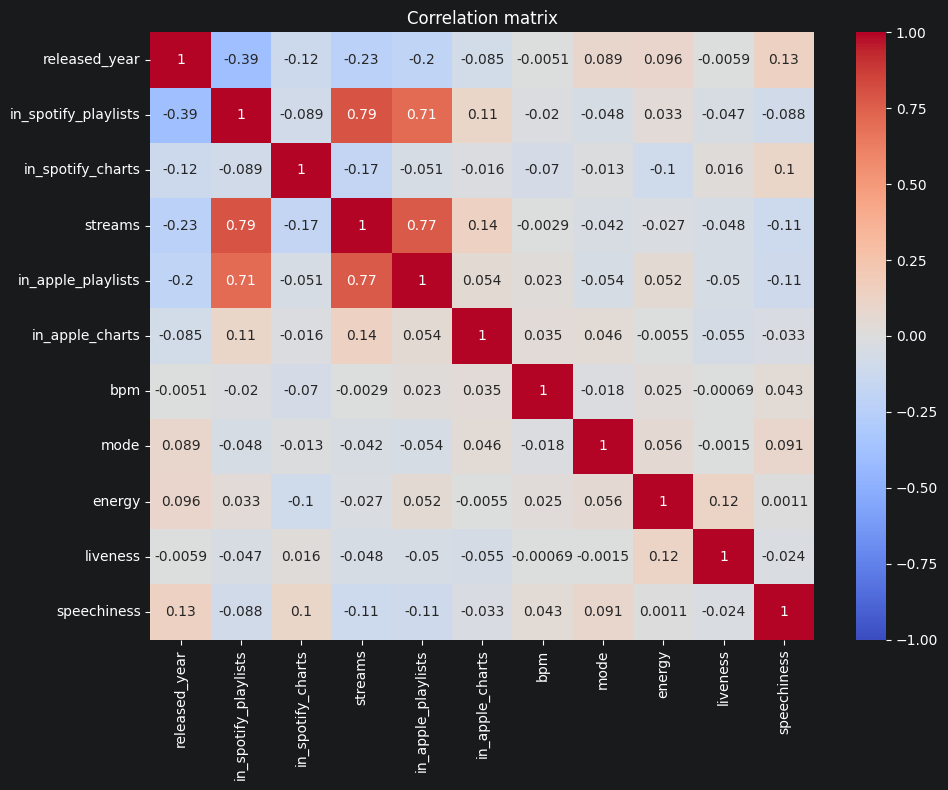

In [6]:
corr_matrix = df_subset.corr(numeric_only=True).round(2)
plt.figure(figsize=(10, 8))
sb.heatmap(df_subset.corr(numeric_only=True), annot=True,
           cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()


### Remove correlated features

The exercise removes `streams` and `in_apple_playlists`.

In [7]:
df_subset = df_subset.drop(columns='streams')
df_subset = df_subset.drop(columns='in_apple_playlists')


## 4. Inspect extreme values

The small plotting function below is reused to inspect several features.

In [8]:
def draw_boxplot(podaci,naslov):
    plt.boxplot(podaci)
    plt.xlabel(naslov)
    plt.show()


In [9]:
print(df_subset.info())


<class 'pandas.DataFrame'>
Index: 952 entries, 0 to 952
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   released_year         952 non-null    int64  
 1   in_spotify_playlists  952 non-null    int64  
 2   in_spotify_charts     952 non-null    float64
 3   in_apple_charts       952 non-null    float64
 4   bpm                   952 non-null    int64  
 5   mode                  952 non-null    int64  
 6   energy                952 non-null    int64  
 7   liveness              952 non-null    int64  
 8   speechiness           952 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 74.4 KB
None


### Released year

View the distribution and an example of winsorization, then remove released year from the clustering features.

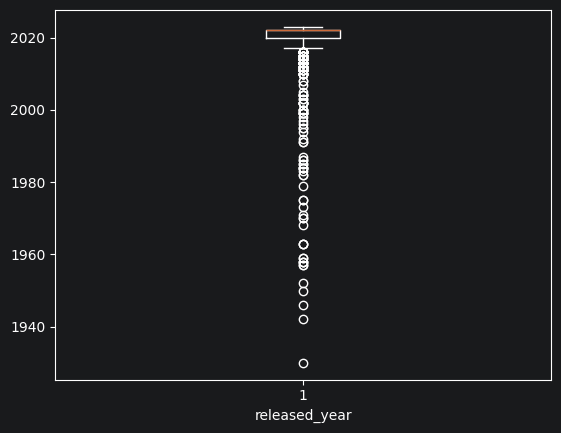

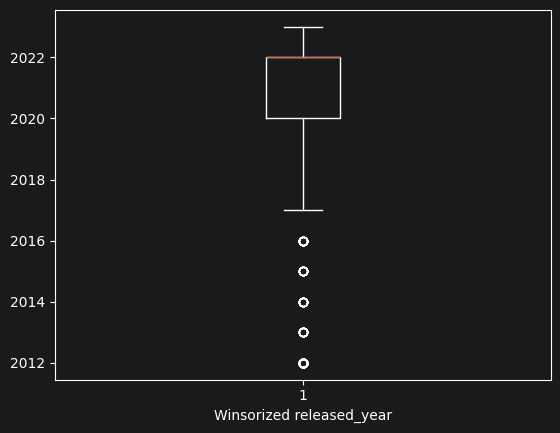

In [10]:
draw_boxplot(df_subset['released_year'],'released_year')


winsorized_data = winsorize(df_subset['released_year'],limits=[0.10,0.00])
draw_boxplot(winsorized_data,'Winsorized released_year')

df_subset = df_subset.drop(columns='released_year')


### Spotify playlists

Inspect unusually high values. The exercise chooses to remove this column.

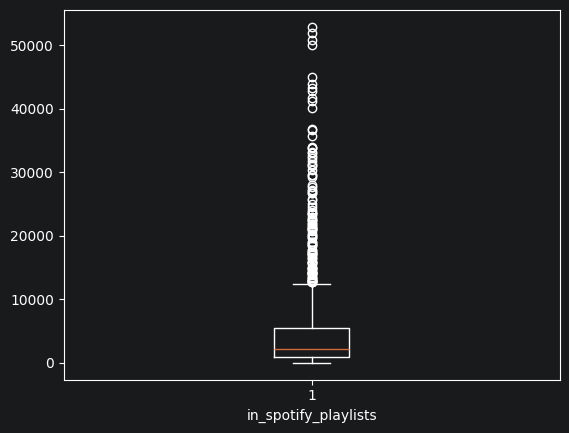

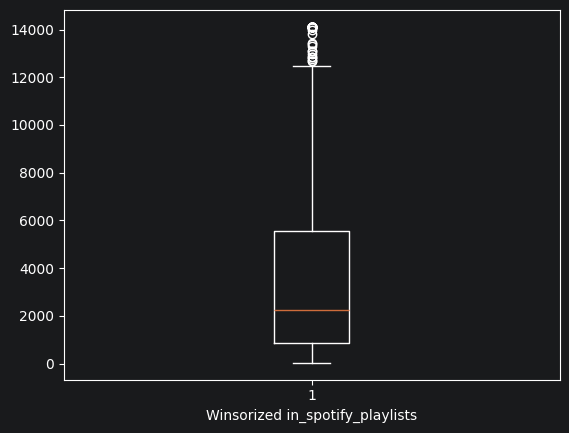

In [11]:
draw_boxplot(df_subset['in_spotify_playlists'],'in_spotify_playlists')

winsorized_data = winsorize(df_subset['in_spotify_playlists'],limits=[0.00,0.10])
draw_boxplot(winsorized_data,'Winsorized in_spotify_playlists')
plt.show()

df_subset = df_subset.drop(columns = 'in_spotify_playlists')


### Spotify charts

Inspect values without further modification.

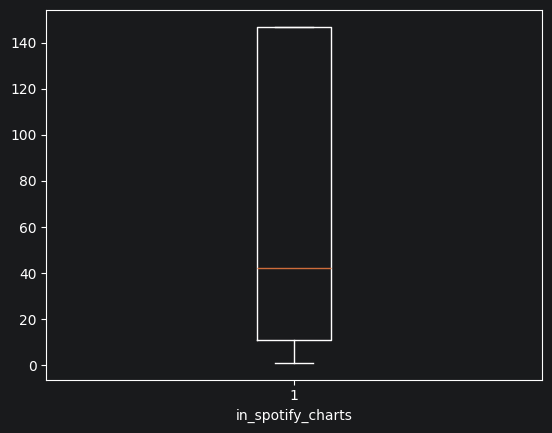

In [12]:
draw_boxplot(df_subset['in_spotify_charts'],'in_spotify_charts')


### Apple charts

After an exploratory winsorization example, the column is removed.

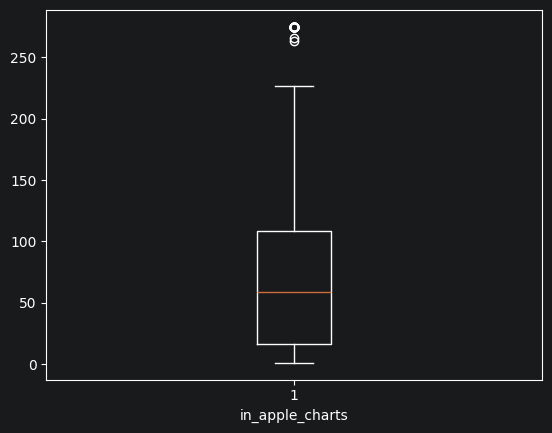

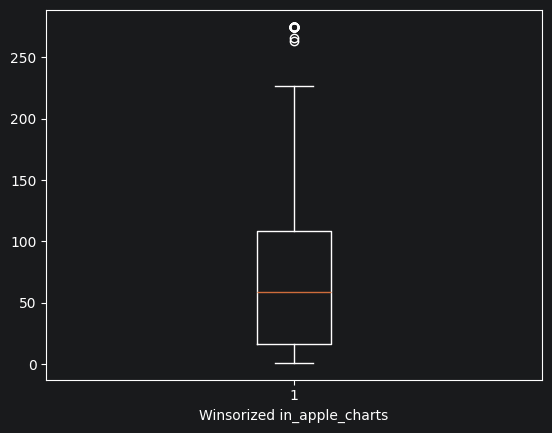

In [13]:
draw_boxplot(df_subset['in_apple_charts'], 'in_apple_charts')


winsorized_data = winsorize(df_subset['in_apple_charts'],limits=[0.00,0.10])
draw_boxplot(winsorized_data,'Winsorized in_apple_charts')
plt.show()


df_subset = df_subset.drop(columns = 'in_apple_charts')


### Beats per minute

Winsorize the upper 10% as practiced in the exercise.

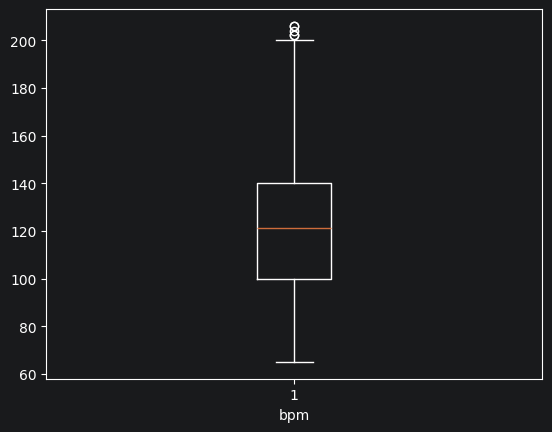

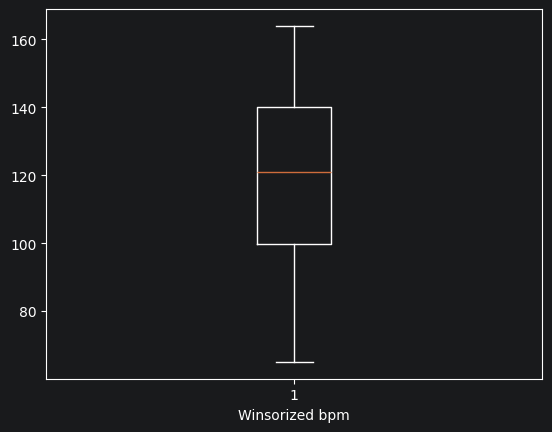

In [14]:
draw_boxplot(df_subset['bpm'],'bpm')

winsorized_data = winsorize(df_subset['bpm'],limits=[0.00,0.10])
draw_boxplot(winsorized_data,'Winsorized bpm')
plt.show()

df_subset['bpm'] = winsorized_data


### Energy

Winsorize the lower 10% as practiced in the exercise.

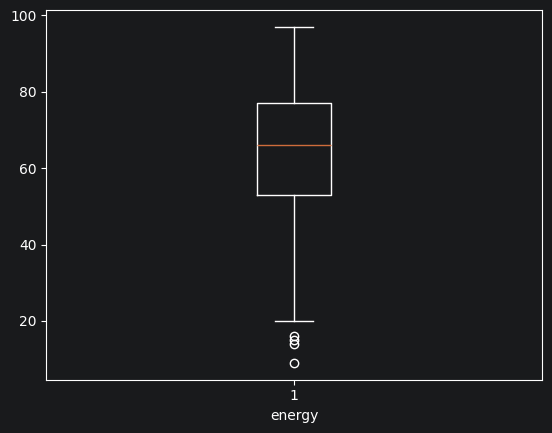

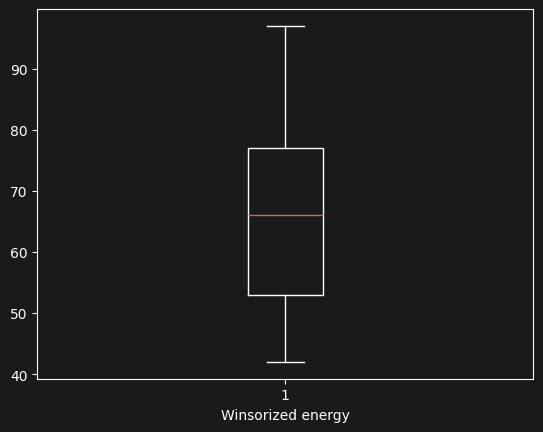

In [15]:
draw_boxplot(df_subset['energy'], 'energy')

winsorized_data = winsorize(df_subset['energy'],limits=[0.10,0.00])
draw_boxplot(winsorized_data,'Winsorized energy')
plt.show()


df_subset['energy'] = winsorized_data


### Liveness

Winsorize the upper 10% as practiced in the exercise.

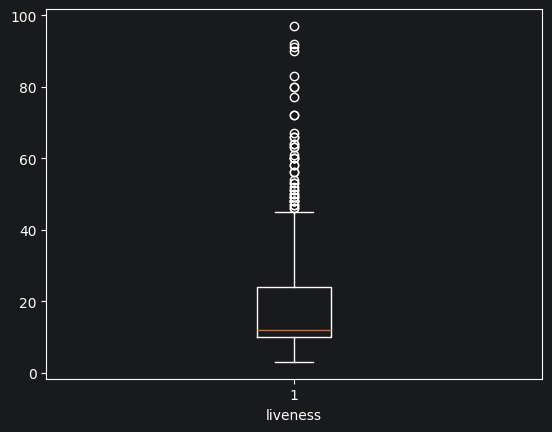

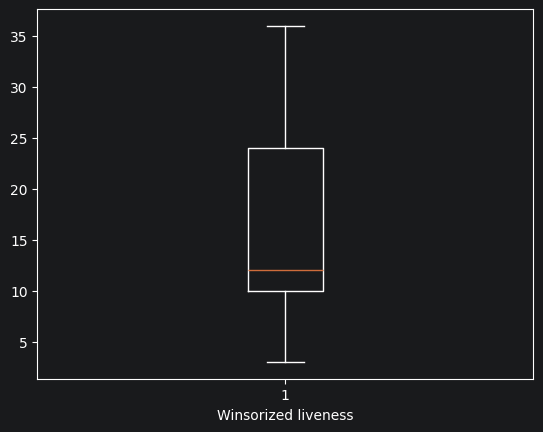

In [16]:
draw_boxplot(df_subset['liveness'], 'liveness')

winsorized_data = winsorize(df_subset['liveness'],limits=[0.00,0.10])
draw_boxplot(winsorized_data,'Winsorized liveness')
plt.show()

df_subset['liveness'] = winsorized_data


### Speechiness

Inspect extremes, then remove speechiness from the final feature set.

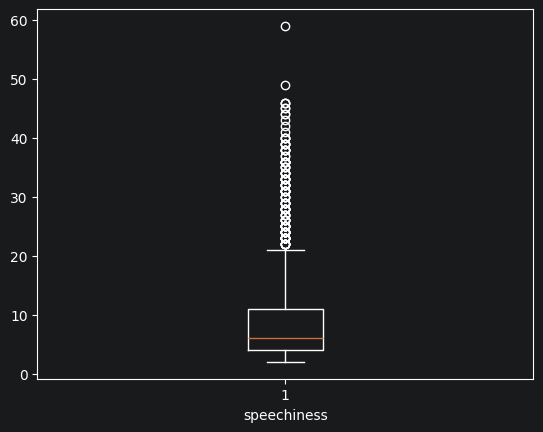

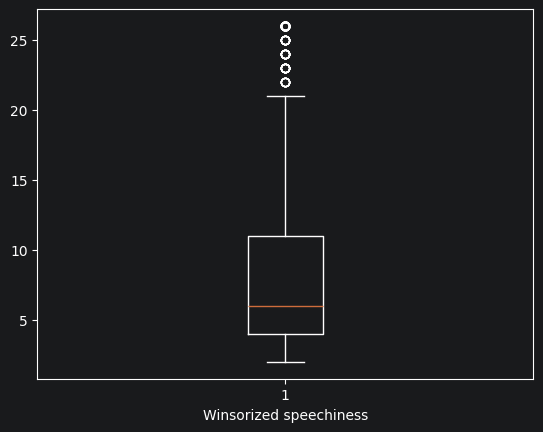

In [17]:
draw_boxplot(df_subset['speechiness'], 'speechiness')

winsorized_data = winsorize(df_subset['speechiness'],limits=[0.00,0.10])
draw_boxplot(winsorized_data,'Winsorized speechiness')
plt.show()


df_subset = df_subset.drop(columns= 'speechiness')


## 5. Scale features

Use `MinMaxScaler` to put numerical attributes in the 0–1 range.

In [18]:
scaler = MinMaxScaler()
temp_data = scaler.fit_transform(df_subset)
df_subset_scaled = pd.DataFrame(temp_data, columns=df_subset.columns)


## 6. Elbow method

Plot the within-cluster sum of squares for 1–10 clusters. The selected number is a visual choice based on this plot.

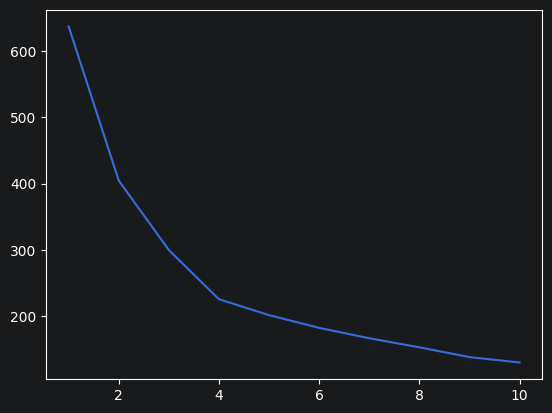

In [19]:
wcss=[]

for i in range(1,11):
    kmeans = cluster.KMeans(n_clusters=i,
                            init = 'k-means++',
                            n_init=10,
                            max_iter=100,
                            random_state=0)
    kmeans.fit(df_subset_scaled)
    wcss.append(kmeans.inertia_)

plt.plot(range(1,11),wcss)
plt.show()


## 7. Fit K-means with two clusters

Use `k-means++` initialization and assign each song a cluster label.

In [20]:
kmeans = cluster.KMeans(n_clusters=2,
                        init='k-means++',
                        max_iter = 100,
                        n_init = 10,
                        random_state=0)
kmeans.fit(df_subset_scaled)

df_subset_scaled['cluster'] = kmeans.labels_


## 8. Compare and interpret the clusters

Side-by-side boxplots allow a basic comparison of feature distributions. Cluster numbers are arbitrary labels, not rankings.

Cluster 1, N =  402
Cluster 2, N =  550


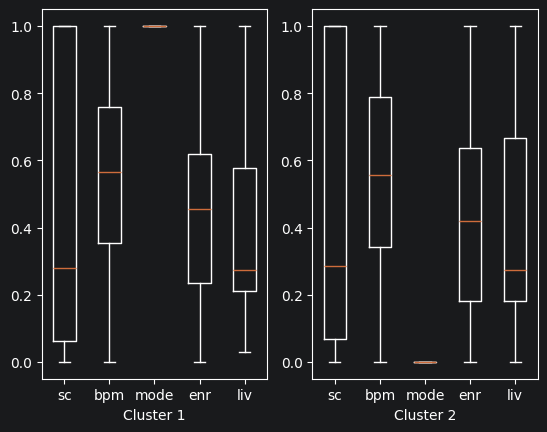

In [21]:
fig,ax = plt.subplots(1,2)

ax[0].boxplot(df_subset_scaled[df_subset_scaled['cluster'] == 0].drop(columns='cluster'), tick_labels = ("sc","bpm","mode","enr", "liv"))
ax[0].set_xlabel("Cluster 1")

ax[1].boxplot(df_subset_scaled[df_subset_scaled['cluster']==1].drop(columns='cluster'), tick_labels = ("sc","bpm","mode","enr", "liv"))
ax[1].set_xlabel("Cluster 2")

print("Cluster 1, N = ", len(df_subset_scaled[df_subset_scaled['cluster']==0]))
print("Cluster 2, N = ", len(df_subset_scaled[df_subset_scaled['cluster']==1]))


### Interpretation of the Clustering Results

**1. Cluster Sizes**

The K-means algorithm divided the dataset into two clusters:

Cluster 1: 402 songs
Cluster 2: 550 songs

Both clusters contain a substantial number of songs, although the second cluster is slightly larger.

**2. Cluster Characteristics**

The most significant difference between the clusters is the musical mode.

Cluster 1 consists of songs in Minor mode (mode = 1), while Cluster 2 consists of songs in Major mode (mode = 0).

For the remaining attributes, including Spotify chart positions, BPM, energy, and liveness, the two clusters have relatively similar distributions.

This suggests that musical mode played the most important role in separating the songs into two groups.

**3. Distribution Within Clusters**

Both clusters are completely homogeneous regarding musical mode, meaning that all songs within each cluster have the same mode value.

However, the other attributes show considerable variation within both clusters.

The distributions of BPM, energy, liveness, and Spotify chart positions overlap significantly between the groups.

**4. Overall Assessment**

Although the K-means algorithm successfully divided the songs into two clusters, the resulting groups are primarily distinguished by musical mode.

Since the other characteristics are relatively similar, it is questionable whether this clustering provides substantial additional insights into the differences between songs.

A different number of clusters or another selection of attributes could potentially reveal more meaningful patterns.

## 9. Conclusions and limitations

- The notebook demonstrates feature preparation, visual exploration, scaling, the elbow method, and K-means clustering.
- The exercise chooses two clusters based on the elbow plot. Their usefulness should be judged by whether the resulting groups are interpretable.
- Song clustering depends strongly on which columns are retained and how they are scaled.
- Winsorization thresholds and replacement of zero chart positions are simplified choices inherited from this practice example, not generally optimal defaults.
- Cluster labels describe similarities in these selected attributes; they do **not** establish objective music genres, quality, or commercial popularity.